# Part I - Ford GoBike Trip Data Exploration
## by Eduardo Nicacio

## Introduction

This notebook explores the **Ford GoBike System Data** for **February 2019**, covering roughly **183,000 bike-share trips** taken across the San Francisco Bay Area. Each record describes one trip: when it started and ended, how long it lasted, which start/end stations and bike were used, and rider attributes such as user type (Subscriber vs. Customer), gender, and birth year.

The exploration follows the **Question → Visualization → Observation** framework to investigate three guiding questions:

1. What does the distribution of **trip duration** look like?
2. Which **user type** (Subscriber vs. Customer) takes longer trips?
3. How do **member age** and **gender** relate to trip duration?

## Preliminary Wrangling

The raw trip records are loaded from the local CSV and inspected for size, column types, and summary statistics before cleaning.

In [1]:
# import all packages and set plots to be embedded inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# project-wide style: one professional blue plus shared seaborn/grid settings
BASE_COLOR = "#2E86AB"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
def add_labels(ax, title, xlabel, ylabel):
    """Apply a consistent title and labeled axes to a plot axes.

    Args:
        ax: matplotlib axes to format.
        title: plot title text.
        xlabel: x-axis label text including units.
        ylabel: y-axis label text including units.

    Returns:
        The same axes object, so calls can be chained.
    """
    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    return ax


def plot_hist(ax, data, column, bins, color=BASE_COLOR):
    """Draw a histogram of a numeric column with consistent styling.

    Args:
        ax: axes to draw on.
        data: DataFrame holding the column.
        column: name of the numeric column to plot.
        bins: sequence of bin edges, or an integer number of bins.
        color: fill color for the bars.

    Returns:
        The same axes object, so calls can be chained.
    """
    ax.hist(data=data, x=column, bins=bins, color=color,
            edgecolor="white", linewidth=0.4)
    return ax


def plot_count(ax, data, column, color=BASE_COLOR):
    """Draw a frequency bar chart ordered by count, with value annotations.

    Bars are ordered by frequency, and each bar is labeled with its count
    and share of trips, so both ranking and imbalance stay readable.

    Args:
        ax: axes to draw on.
        data: DataFrame holding the column.
        column: name of the categorical column to plot.
        color: fill color for the bars.

    Returns:
        The same axes object, so calls can be chained.
    """
    counts = data[column].value_counts()  # order bars by frequency
    ax.bar(x=range(len(counts)), height=counts.values, color=color)
    ax.set_xticks(range(len(counts)), counts.index)  # category names under bars
    total = counts.sum()  # used to convert each count into a share
    for i, value in enumerate(counts.values):
        ax.text(i, value + total * 0.01, f"{value:,}\n({value / total:.1%})",
                ha="center", va="bottom", fontsize=10)
    return ax


def pivot_hour_by_day(data):
    """Build a day-of-week x hour-of-day pivot table of trip counts.

    Rows are ordered Monday->Sunday and all 24 hours are kept, so heatmaps
    built later always communicate the same grid shape.

    Args:
        data: DataFrame with `day_of_week` and `hour_of_day` columns.

    Returns:
        A 7x24 DataFrame of integer trip counts.
    """
    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
                 "Friday", "Saturday", "Sunday"]
    # count trips per day/hour combination, then spread hours into columns
    piv = data.groupby(["day_of_week", "hour_of_day"], observed=True).size().unstack(fill_value=0)
    piv = piv.reindex(index=day_order, columns=range(24), fill_value=0)
    return piv

In [3]:
# load the raw trip table and report its size and column types
trips_raw = pd.read_csv("data/201902-fordgobike-tripdata.csv")

print("Raw shape (rows, columns):", trips_raw.shape)
print(trips_raw.dtypes)
trips_raw.head()

Raw shape (rows, columns): (183412, 16)
duration_sec                 int64
start_time                     str
end_time                       str
start_station_id           float64
start_station_name             str
start_station_latitude     float64
start_station_longitude    float64
end_station_id             float64
end_station_name               str
end_station_latitude       float64
end_station_longitude      float64
bike_id                      int64
user_type                      str
member_birth_year          float64
member_gender                  str
bike_share_for_all_trip        str
dtype: object


,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
0,52185,2019-02-28 17:32:10.1450,2019-03-01 08:01:55.9750,21.0,Montgomery St BART Station (Market St at 2nd St),37.789625,-122.400811,13.0,Commercial St at Montgomery St,37.794231,-122.402923,4902,Customer,1984.0,Male,No
1,42521,2019-02-28 18:53:21.7890,2019-03-01 06:42:03.0560,23.0,The Embarcadero at Steuart St,37.791464,-122.391034,81.0,Berry St at 4th St,37.775880,-122.393170,2535,Customer,NaN,NaN,No
2,61854,2019-02-28 12:13:13.2180,2019-03-01 05:24:08.1460,86.0,Market St at Dolores St,37.769305,-122.426826,3.0,Powell St BART Station (Market St at 4th St),37.786375,-122.404904,5905,Customer,1972.0,Male,No
3,36490,2019-02-28 17:54:26.0100,2019-03-01 04:02:36.8420,375.0,Grove St at Masonic Ave,37.774836,-122.446546,70.0,Central Ave at Fell St,37.773311,-122.444293,6638,Subscriber,1989.0,Other,No
4,1585,2019-02-28 23:54:18.5490,2019-03-01 00:20:44.0740,7.0,Frank H Ogawa Plaza,37.804562,-122.271738,222.0,10th Ave at E 15th St,37.792714,-122.248780,4898,Subscriber,1974.0,Male,Yes


In [4]:
# schema and memory overview of the raw table
trips_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 183412 entries, 0 to 183411
Data columns (total 16 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   duration_sec             183412 non-null  int64  
 1   start_time               183412 non-null  str    
 2   end_time                 183412 non-null  str    
 3   start_station_id         183215 non-null  float64
 4   start_station_name       183215 non-null  str    
 5   start_station_latitude   183412 non-null  float64
 6   start_station_longitude  183412 non-null  float64
 7   end_station_id           183215 non-null  float64
 8   end_station_name         183215 non-null  str    
 9   end_station_latitude     183412 non-null  float64
 10  end_station_longitude    183412 non-null  float64
 11  bike_id                  183412 non-null  int64  
 12  user_type                183412 non-null  str    
 13  member_birth_year        175147 non-null  float64
 14  member_gender  

In [5]:
# summary statistics for the raw numeric columns
trips_raw.describe()

,duration_sec,start_station_id,start_station_latitude,start_station_longitude,end_station_id,end_station_latitude,end_station_longitude,bike_id,member_birth_year
count,183412.000000,183215.000000,183412.000000,183412.000000,183215.000000,183412.000000,183412.000000,183412.000000,175147.000000
mean,726.078435,138.590427,37.771223,-122.352664,136.249123,37.771427,-122.352250,4472.906375,1984.806437
std,1794.389780,111.778864,0.099581,0.117097,111.515131,0.099490,0.116673,1664.383394,10.116689
min,61.000000,3.000000,37.317298,-122.453704,3.000000,37.317298,-122.453704,11.000000,1878.000000
25%,325.000000,47.000000,37.770083,-122.412408,44.000000,37.770407,-122.411726,3777.000000,1980.000000
50%,514.000000,104.000000,37.780760,-122.398285,100.000000,37.781010,-122.398279,4958.000000,1987.000000
75%,796.000000,239.000000,37.797280,-122.286533,235.000000,37.797320,-122.288045,5502.000000,1992.000000
max,85444.000000,398.000000,37.880222,-121.874119,398.000000,37.880222,-121.874119,6645.000000,2001.000000


In [6]:
def clean_bike_data(raw):
    """Clean the raw Ford GoBike trip table and derive analysis columns.

    Steps:
        1. Drop rows with null or zero duration.
        2. Convert `duration_sec` to minutes.
        3. Parse `start_time`; derive `hour_of_day` and `day_of_week`.
        4. Derive `member_age`; keep plausible ages (16-80).
        5. Cast descriptive columns to category dtype.

    Args:
        raw: DataFrame exactly as loaded from the raw CSV.

    Returns:
        A cleaned DataFrame with the derived analysis columns added.
    """
    trips = raw.copy()

    # step 1: keep only rows with a usable, positive trip duration
    trips = trips[trips["duration_sec"].notna() & (trips["duration_sec"] > 0)]

    # step 2: minutes are more readable than seconds for this range of trips
    trips["duration_min"] = trips["duration_sec"] / 60.0

    # step 3: parse timestamps and derive the time-of-day features
    trips["start_time"] = pd.to_datetime(trips["start_time"])
    trips["hour_of_day"] = trips["start_time"].dt.hour
    day_dtype = pd.api.types.CategoricalDtype(
        categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)
    trips["day_of_week"] = trips["start_time"].dt.day_name().astype(day_dtype)

    # step 4: age from birth year, filtered to plausible ages only
    trips["member_age"] = 2019 - trips["member_birth_year"]
    trips = trips[trips["member_age"].between(16, 80)]

    # step 5: descriptive columns take few values; category dtype saves memory
    for column in ["user_type", "member_gender", "bike_share_for_all_trip"]:
        trips[column] = trips[column].astype("category")

    return trips

# apply the cleaning routine and report the resulting shape
trips = clean_bike_data(trips_raw)
print("Cleaned shape (rows, columns):", trips.shape)
trips.head()

Cleaned shape (rows, columns): (174955, 20)


,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip,duration_min,hour_of_day,day_of_week,member_age
0,52185,2019-02-28 17:32:10.145,2019-03-01 08:01:55.9750,21.0,Montgomery St BART Station (Market St at 2nd St),37.789625,-122.400811,13.0,Commercial St at Montgomery St,37.794231,-122.402923,4902,Customer,1984.0,Male,No,869.750000,17,Thursday,35.0
2,61854,2019-02-28 12:13:13.218,2019-03-01 05:24:08.1460,86.0,Market St at Dolores St,37.769305,-122.426826,3.0,Powell St BART Station (Market St at 4th St),37.786375,-122.404904,5905,Customer,1972.0,Male,No,1030.900000,12,Thursday,47.0
3,36490,2019-02-28 17:54:26.010,2019-03-01 04:02:36.8420,375.0,Grove St at Masonic Ave,37.774836,-122.446546,70.0,Central Ave at Fell St,37.773311,-122.444293,6638,Subscriber,1989.0,Other,No,608.166667,17,Thursday,30.0
4,1585,2019-02-28 23:54:18.549,2019-03-01 00:20:44.0740,7.0,Frank H Ogawa Plaza,37.804562,-122.271738,222.0,10th Ave at E 15th St,37.792714,-122.248780,4898,Subscriber,1974.0,Male,Yes,26.416667,23,Thursday,45.0
5,1793,2019-02-28 23:49:58.632,2019-03-01 00:19:51.7600,93.0,4th St at Mission Bay Blvd S,37.770407,-122.391198,323.0,Broadway at Kearny,37.798014,-122.405950,5200,Subscriber,1959.0,Male,No,29.883333,23,Thursday,60.0


In [7]:
# quick numeric check on the two key derived columns after cleaning
trips[["duration_min", "hour_of_day", "member_age"]].describe()

,duration_min,hour_of_day,member_age
count,174955.000000,174955.000000,174955.000000
mean,11.741977,13.456232,34.121997
std,27.373897,4.734615,9.875893
min,1.016667,0.000000,18.000000
25%,5.383333,9.000000,27.000000
50%,8.516667,14.000000,32.000000
75%,13.150000,17.000000,39.000000
max,1409.133333,23.000000,80.000000


### What is the structure of your dataset?

After cleaning, the dataset contains **174,955 bike trips and 20 columns** (started at 183,412 × 16; 8,457 rows were dropped by the age filter (none by the duration filter), and four columns - `duration_min`, `hour_of_day`, `day_of_week`, `member_age` - were derived). Each row is one trip. The columns mix **numeric** measures (`duration_min`, `member_age`, station coordinates), **datetime-derived** features (`hour_of_day`, `day_of_week` as an ordered categorical Monday→Sunday), and **categorical** descriptors (`user_type`, `member_gender`, `bike_share_for_all_trip`).

### What is/are the main feature(s) of interest in your dataset?

The main feature of interest is **`duration_min`** - how long a rider keeps a bike. It directly reflects how the system is used (short commutes vs. longer leisure outings) and pricing pressure on the system.

### What features in the dataset do you think will help support your investigation?

**`user_type`** (Subscriber vs. Customer) is expected to separate commuting behavior from leisure behavior, and so are the time features **`hour_of_day`** and **`day_of_week`**. **`member_age`** (derived from `member_birth_year`) and **`member_gender`** allow checking whether rider demographics relate to trip length. Station names/coordinates are out of scope here because the focus is on rider behavior, not station geography.

## Univariate Exploration

In this section I look at individual variables with the Question → Visualization → Observation framework, starting with the main feature of interest, trip duration.

**Q1. What is the distribution of trip duration?** (Duration spans multiple orders of magnitude, so I plot it directly on a log-scaled axis with log-spaced bins instead of squeezing the linear tail off the chart.)

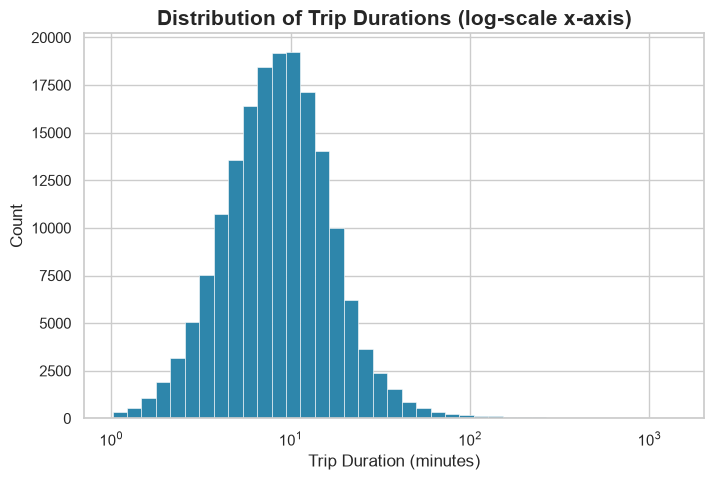

In [8]:
# log-spaced bins are needed because durations span ~1 to ~1400 minutes
duration_bins = np.logspace(np.log10(trips["duration_min"].min()),
                            np.log10(trips["duration_min"].max()), 40)

fig, ax = plt.subplots()
plot_hist(ax, trips, "duration_min", duration_bins)
ax.set_xscale("log")
add_labels(ax, "Distribution of Trip Durations (log-scale x-axis)",
           "Trip Duration (minutes)", "Count");

**O1. Observations:** Trip duration is **strongly right-skewed** on a linear scale, so the log-scale view was essential. On the log axis the distribution looks roughly unimodal and near-log-normal, peaking around **9–11 minutes** (modal log-bin 9.4–11.3), with median ≈ 8.5 min. The bulk of trips are **well under 30 minutes** (only ~3.5% exceed 30 min, ~0.8% exceed 60 min), while a thin tail stretches to ~1,400 minutes - multi-hour or possibly misplaced bike trips. The transformation was worth it: on a linear axis nearly the entire mass would collapse into the first bin.

**Q2. How are user types distributed?** (The categorical user-type variable counts Subscribers vs. Customers; a frequency bar ordered by count makes the imbalance explicit, with counts and shares annotated on the bars.)

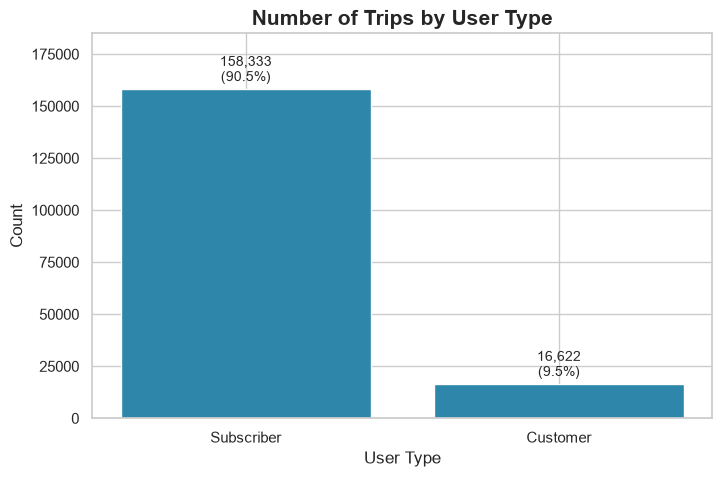

In [9]:
fig, ax = plt.subplots()
plot_count(ax, trips, "user_type")
ax.set_ylim(0, 185000)  # headroom so the annotations above bars are not clipped
add_labels(ax, "Number of Trips by User Type", "User Type", "Count");

**O2. Observations:** The system is overwhelmingly a membership program: **Subscribers took 158,333 trips (90.5%)** versus **16,622 trips (9.5%)** for casual Customers - roughly a 10-to-1 ratio. Because the two groups use the system so differently, this split is exactly where I will look for duration differences in the bivariate section.

**Q3. What is the age distribution of members?** (Age was derived from birth year and bounded to plausible values, 16–80; a plain histogram with 30 bins shows where riders cluster.)

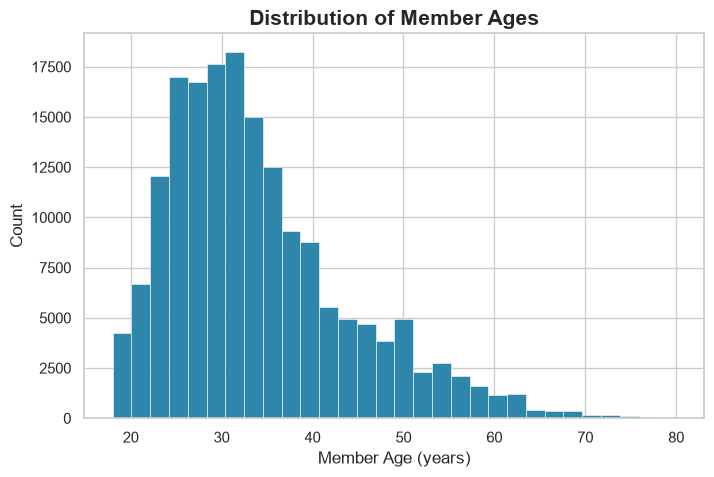

In [10]:
fig, ax = plt.subplots()
plot_hist(ax, trips, "member_age", 30)  # 30 bins per the analysis plan
add_labels(ax, "Distribution of Member Ages", "Member Age (years)", "Count");

**O3. Observations:** Ages are **right-skewed with a clear peak in the late 20s to early 30s** - half of all riders are between 27 and 39 (median = 32, mean ≈ 34.1). Membership falls off steadily after the 30s, and fewer than 2% of riders are older than 60, so the 16–80 age filter removed only implausible or extreme values without carving away a real population.

### Discuss the distribution(s) of your variable(s) of interest. Were there any unusual points? Did you need to perform any transformations?

The variable of interest, `duration_min`, is strongly **right-skewed**: half of all trips finish within ~8.5 minutes, 75% within ~13.2 minutes, but values stretch out to ~1,409 minutes (about 23.5 hours). The extreme long tail is the unusual point of this section - spanning roughly three orders of magnitude, it forced a transformation: I plotted on a **log-scaled x-axis with log-spaced bins**, which turned the skewed mass into an interpretable near-log-normal peak (6–12 minutes).

### Of the features you investigated, were there any unusual distributions? Did you perform any operations on the data to tidy, adjust, or change the form of the data? If so, why did you do this?

Yes, four adjustments were made, all during wrangling. (1) I dropped rows with null or zero `duration_sec` (the filter removed none - every trip has a positive duration) and converted it to `duration_min`, because zero-duration rows cannot represent real rides and minutes are more interpretable. (2) `member_age` was computed from `member_birth_year`; riders outside **16–80** years were dropped (8,457 rows: 8,265 blank birth years, 192 out-of-range ages), since implausible birth years (e.g., 1900 or blank) would distort the age analysis. (3) `start_time` was parsed into `hour_of_day` and ordered `day_of_week` because travel-behavior patterns live at these time scales. (4) `user_type`, `member_gender`, and `bike_share_for_all_trip` were cast to **category dtype** - they contain few distinct values and this is memory-efficient and makes ordered plotting explicit. The user-type and age distributions themselves showed no surprises beyond expected skew.

## Bivariate Exploration

Here pairs of variables are examined, with trip duration as the focus. The variables below were all introduced in the univariate section.

**Q4. Is there a relationship between member age and trip duration?** (Both variables are continuous; a scatter shows whether older riders behave differently. A log-scaled y-axis plus very low alpha and rasterization keep the ~175k overlapping points readable.)

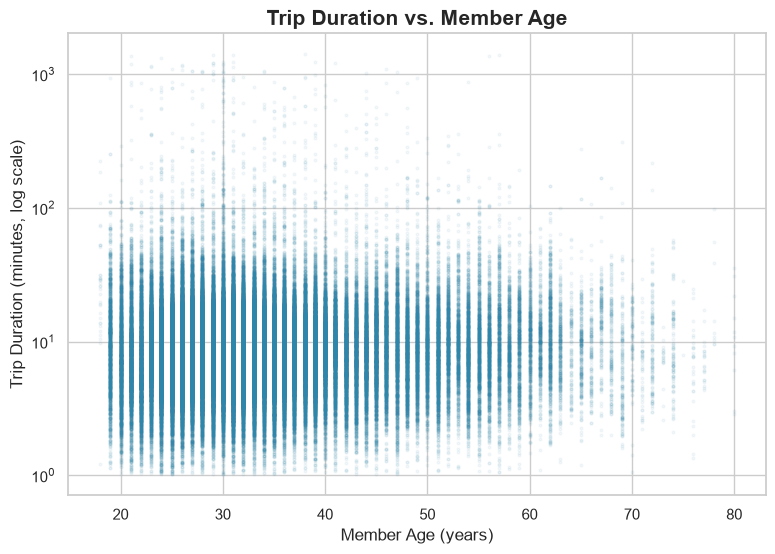

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
# rasterized=True + alpha=0.05 combat overplotting from ~175k points
ax.scatter(data=trips, x="member_age", y="duration_min",
           s=4, alpha=0.05, rasterized=True, color=BASE_COLOR)
ax.set_yscale("log")
add_labels(ax, "Trip Duration vs. Member Age", "Member Age (years)",
           "Trip Duration (minutes, log scale)");

**O4. Observations:** There is **no strong linear trend** between age and duration - the solid band of trips sits around 5–20 minutes for every age, and the correlation between age and log-duration is essentially zero (r ≈ +0.03). The main age-related finding is that **even the spread barely moves with age**: the 90th percentile stays near 19–23 minutes in every age band, and if anything the oldest band (56+) shows the slightly longest tail. Age alone is a weak direct predictor of trip length.

**Q5. Does trip duration differ by user type?** (A numeric variable vs. a two-level categorical variable is a classic box-plot case; the log-scaled y-axis keeps the heavy tail from flattening the boxes.)

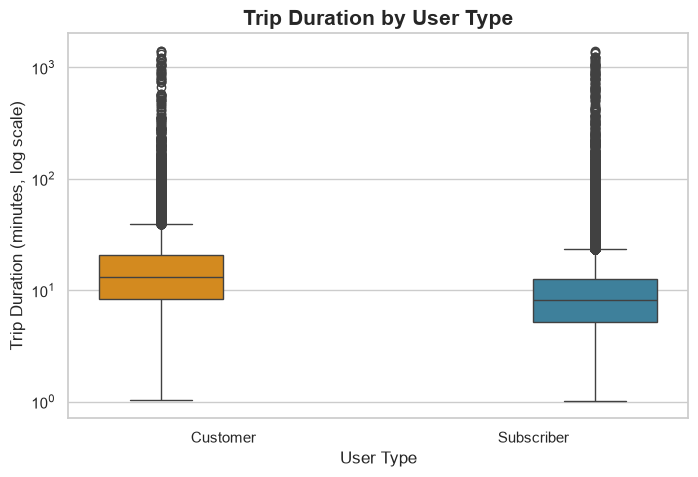

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
# two distinct hues flag the contrast; hue mirrors x to keep seaborn 0.13 happy
sns.boxplot(data=trips, x="user_type", y="duration_min", hue="user_type",
            legend=False,
            palette={"Subscriber": "#2E86AB", "Customer": "#F18F01"}, ax=ax)
ax.set_yscale("log")
add_labels(ax, "Trip Duration by User Type", "User Type",
           "Trip Duration (minutes, log scale)");

**O5. Observations:** **Customers take noticeably longer trips than Subscribers on every summary statistic** - median 13.0 min vs. 8.2 min, and mean 21.8 min vs. 10.7 min, i.e. Customers average roughly **2× the trip duration**. The Customer box is taller: its interquartile range (8.3–20.5 min) sits above the Subscriber median (8.2 min), and Customer trips exceed an hour at ~10× the Subscriber rate (4.2% vs. 0.4%). This fits the interpretation that Subscribers use bikes for quick commutes while Customers ride for leisure or tourism.

**Q6. When are trips most frequent across the week?** (Two categorical time variables - hour of day and day of week - are naturally summarized by a heatmap of trip counts, since a clustered version would need 24 bars per day.)

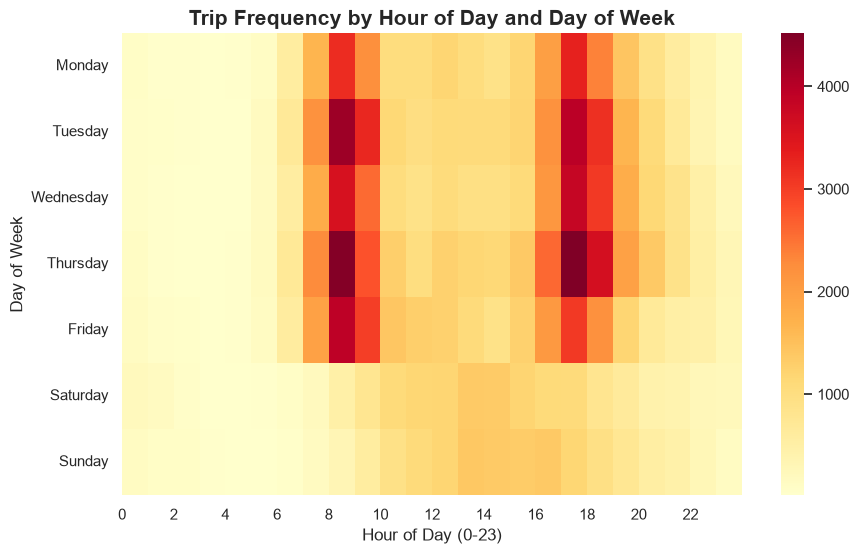

In [13]:
hour_day = pivot_hour_by_day(trips)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(hour_day, annot=False, cmap="YlOrRd", ax=ax)
# keep only every second hour tick so the x-axis stays readable
ax.set_xticks(range(0, 24, 2), labels=range(0, 24, 2))
add_labels(ax, "Trip Frequency by Hour of Day and Day of Week",
           "Hour of Day (0-23)", "Day of Week");

**O6. Observations:** Weekdays show two sharp **commute-hour spikes at 8 AM and 5–6 PM (17:00–18:00)** (Tuesday and Thursday are the busiest days), and the 8 AM/5 PM ridges extend across Monday–Friday. Weekends look completely different: the rush-hour ridges dissolve into a broad, warm **midday band (roughly 10 AM–4 PM)**, consistent with leisure riding. The trough sits at 3 AM Monday–Friday (4 AM on weekends) - the weakest hours everywhere.

### Talk about some of the relationships you observed in this part of the investigation. How did the feature(s) of interest vary with other features in the dataset?

Trip duration varied clearly with **user type** but hardly at all with **age**: Customers ride roughly twice as long as Subscribers (13.0 vs. 8.2 minutes median; 21.8 vs. 10.7 minutes mean), while age shows no meaningful trend in duration (r ≈ 0.03 on the log scale) - the duration spread stays flat across age bands, with none standing out. Time-of-day, explored through the day × hour heatmap, varies with usage volume exactly as a two-purpose system would: weekday 8 AM / 5–6 PM commute spikes versus broad weekend midday leisure bands.

### Did you observe any interesting relationships between the other features (not the main feature(s) of interest)?

The time structure itself was the most interesting "other" relationship: the heatmap shows that the weekday/weekend contrast in usage shape is as strong as the volume difference (Tuesday–Thursday are the heaviest days, while Saturday and Sunday average about half as many trips per day (14.5k vs. 29.2k) with flatter, midday-centered curves). Also worth noting: 90.5% of trips come from Subscribers, so the weekday commute pattern is largely *their* pattern - a hypothesis the multivariate section can test by separating user types within the hour-of-day distribution.

## Multivariate Exploration

Plots here combine three or more variables. The bivariate findings above motivate two focused views: hour-of-day rhythm **by user type**, and age–duration interaction **by gender**.

**Q7. Does the hour-of-day trip pattern differ between Subscribers and Customers?** (The heatmap mixes the two user types together; a faceted, shared-y histogram of `hour_of_day` per user type isolates each group's rhythm on a comparable scale.)

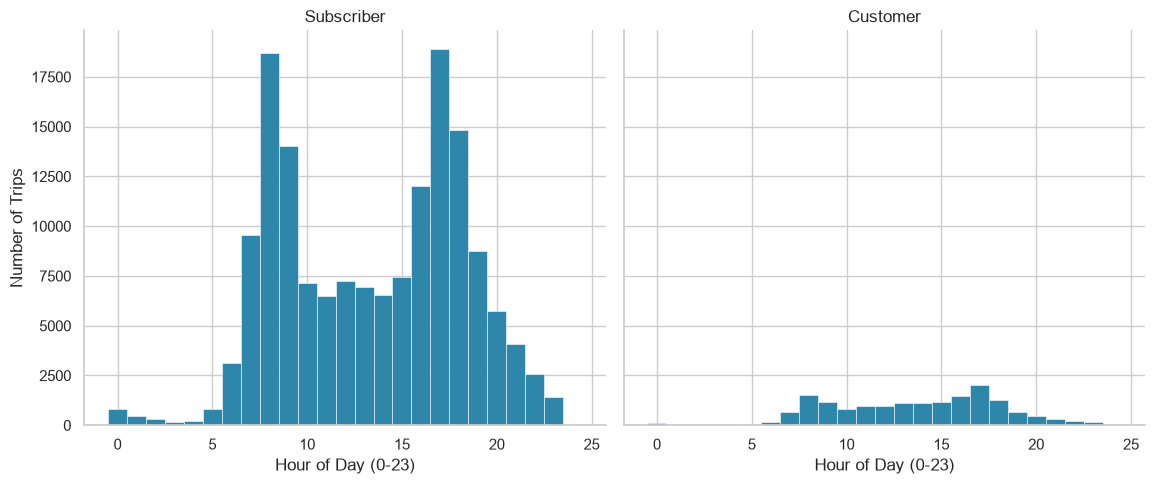

In [14]:
# faceted histograms share the y-axis so the two rhythms compare directly
# col_order keeps the Subscriber-first reading order used in the narrative
g = sns.FacetGrid(data=trips, col="user_type",
                  col_order=["Subscriber", "Customer"],
                  height=5, aspect=1.15, sharey=True)
g.map(plt.hist, "hour_of_day", bins=np.arange(-0.5, 25.5, 1),
      color=BASE_COLOR, edgecolor="white", linewidth=0.4)
g.set_titles("{col_name}")
g.set_axis_labels("Hour of Day (0-23)", "Number of Trips");

**O7. Observations:** The two rhythms are visibly different. **Subscribers peak sharply at commute hours** - 8 AM and 5–6 PM are the tallest bars, with a nearly twin-spike profile repeated on weekdays. **Customers are far flatter through waking hours**: 46% of their trips land in the 10 AM–4 PM window, and their busiest single hour (5 PM, 2,024 trips) is only a faint bump next to Subscribers' 18,886. Since Customers are only ~9.5% of trips, their flatness barely registers in the combined heatmap - the facet view is what makes their leisure-oriented rhythm visible.

**Q8. How do age, trip duration, and gender interact?** (A scatter of age vs. log-duration gains a third dimension by color-encoding `member_gender`. All three levels stay - 3,649 "Other" rides is a meaningful count - with pinpoint-sized, alpha-faded points to limit overplotting.)

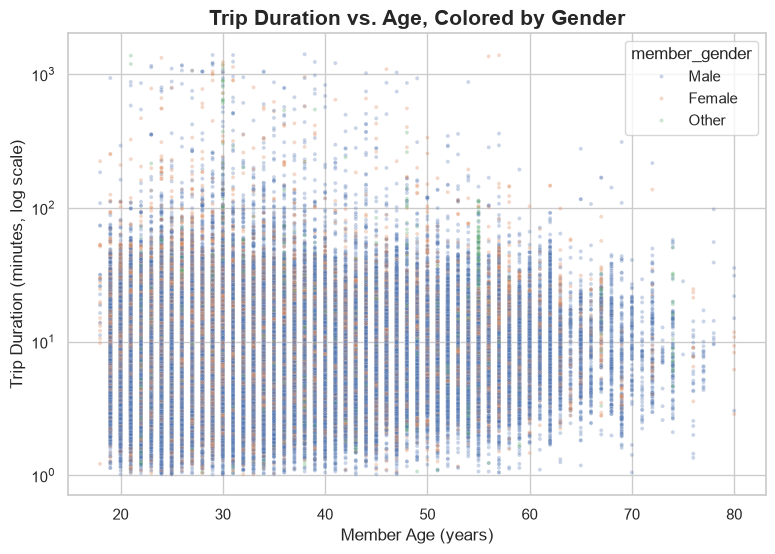

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))
# "Other" gender rides exist in meaningful numbers (3,649), so all three
# levels stay color-coded; small semi-transparent points limit overplotting
sns.scatterplot(data=trips, x="member_age", y="duration_min",
                hue="member_gender", hue_order=["Male", "Female", "Other"],
                s=8, alpha=0.3, ax=ax)
ax.set_yscale("log")
add_labels(ax, "Trip Duration vs. Age, Colored by Gender",
           "Member Age (years)", "Trip Duration (minutes, log scale)");

**O8. Observations:** The age–duration cloud looks essentially the **same shape for every gender** - the dense horizontal band around 5–20 minutes repeats for Male, Female, and Other, and median durations are close (Male 8.2 min, Female 9.5 min, Other 9.2 min). The clearest gender difference is **volume, not length**: Male riders occupy most of the plot's ink (74.6% of trips vs. 23.3% Female, 2.1% Other), with Male riders peaking most strongly in the 30s age band. Female and Other riders' slight upward shift in typical duration is visible but modest.

### Talk about some of the relationships you observed in this part of the investigation. Were there features that strengthened each other in terms of looking at your feature(s) of interest?

Yes - user type and time of day strengthened each other: the combined heatmap's commute spikes turned out to be almost entirely a **Subscriber** phenomenon, while Customers own a flatter, midday-centered rhythm. That interaction explains *why* duration differs so strongly by user type (commute utility trips vs. leisure trips) even though hour of day alone barely moves duration. Gender, by contrast, added little explanatory power on top of age and duration: the age–duration cloud is nearly identical across the three gender levels, with volume (Male ≈ 3× Female rides) being the notable, but second-order, difference.

### Were there any interesting or surprising interactions between features?

Two stood out. First, the faceted hour-of-day view shows that Customers - despite being only 9.5% of trips - shape the weekend/midday pattern inferred from the combined heatmap, so two user types are hiding inside one apparently simple time pattern. Second, gender produces a large ridership-volume gap but almost no duration or age-pattern gap, an interaction one might misread in the opposite direction. Beyond that, no surprising *interaction* effects: age's near-zero relationship with duration holds without modification when gender is layered in.

In [16]:
# claim-verification: every number quoted in this notebook's markdown,
# recomputed here so each sentence traces back to a printed value

# duration distribution (O1, Conclusions)
duration = trips["duration_min"]
print("duration median (min):", round(duration.median(), 2))
print("trips > 30 min: {:.1%} | trips > 60 min: {:.2%}".format(
    (duration > 30).mean(), (duration > 60).mean()))
print("duration range: {:.2f} to {:.0f} min ({:.1f} hours)".format(
    duration.min(), duration.max(), duration.max() / 60))

# user-type counts/shares + duration summaries (O2, O5)
print(trips.groupby("user_type", observed=True)["duration_min"]
      .agg(["count", "median", "mean", "max"]).round(2))
print("share of each group's trips > 60 min (%):")
print((trips.groupby("user_type", observed=True)["duration_min"]
       .apply(lambda d: (d > 60).mean()) * 100).round(2))

# age distribution (O3)
age = trips["member_age"]
print("age quartiles 25/50/75:", age.quantile([.25, .5, .75]).to_list(),
      "| mean:", round(age.mean(), 1),
      "| riders > 60: {:.1%}".format((age > 60).mean()))

# age-band duration profile + correlation (O4)
for low, high in [(16, 25), (26, 35), (36, 45), (46, 55), (56, 80)]:
    band = duration[trips["member_age"].between(low, high)]
    print("age {}-{}: median {:.1f} | 90th pct {:.1f} | mean {:.1f}".format(
        low, high, band.median(), band.quantile(.9), band.mean()))
print("pearson r (age vs log10 duration):", round(age.corr(np.log10(duration)), 3))

# time patterns (O6)
hour_day = pivot_hour_by_day(trips)
weekday_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekday_hours = hour_day.loc[weekday_days].sum()
print("weekday top-3 hours:", weekday_hours.sort_values(ascending=False).head(3).to_dict())
per_day = hour_day.sum(axis=1).sort_values(ascending=False)
print("trips per day, busiest first:", {day: int(n) for day, n in per_day.items()})
weekend = hour_day.loc[["Saturday", "Sunday"]]
print("weekend share in 10 AM-4 PM: {:.0%}".format(
    weekend[list(range(10, 17))].values.sum() / weekend.values.sum()))
print("trough hour per day:", {day: int(row.idxmin()) for day, row in hour_day.iterrows()})
print("average weekday trips per day:", int(hour_day.loc[weekday_days].values.sum() / 5),
      "| average weekend day:", int(weekend.values.sum() / 2))

# user-type rhythm (O7)
for user in ["Subscriber", "Customer"]:
    hour_counts = trips[trips["user_type"] == user].groupby("hour_of_day", observed=True).size()
    mid_share = hour_counts.loc[10:16].sum() / hour_counts.sum()
    print(user, "| busiest hour:", int(hour_counts.idxmax()), "with",
          int(hour_counts.max()), "trips | share 10 AM-4 PM: {:.0%}".format(mid_share))

# gender (O8, Conclusions)
print(trips["member_gender"].value_counts())
print((trips["member_gender"].value_counts(normalize=True) * 100).round(1))
print(trips.groupby("member_gender", observed=True)["duration_min"].median().round(2))

duration median (min): 8.52
trips > 30 min: 3.4% | trips > 60 min: 0.79%
duration range: 1.02 to 1409 min (23.5 hours)
             count  median   mean      max
user_type                                 
Customer     16622   13.00  21.84  1391.98
Subscriber  158333    8.17  10.68  1409.13
share of each group's trips > 60 min (%):
user_type
Customer      4.22
Subscriber    0.43
Name: duration_min, dtype: float64
age quartiles 25/50/75: [27.0, 32.0, 39.0] | mean: 34.1 | riders > 60: 1.9%
age 16-25: median 8.0 | 90th pct 19.5 | mean 11.4
age 26-35: median 8.7 | 90th pct 19.1 | mean 11.8
age 36-45: median 8.4 | 90th pct 18.7 | mean 11.6
age 46-55: median 8.6 | 90th pct 21.0 | mean 12.3
age 56-80: median 9.2 | 90th pct 22.5 | mean 12.7
pearson r (age vs log10 duration): 0.029
weekday top-3 hours: {8: 19410, 17: 18663, 18: 14396}
trips per day, busiest first: {'Thursday': 33712, 'Tuesday': 30594, 'Wednesday': 28426, 'Friday': 27640, 'Monday': 25633, 'Sunday': 14512, 'Saturday': 14438}
weeke

## Conclusions

Main findings from the exploratory analysis:

- **Trip durations are heavily right-skewed**; after a log-scale transformation the distribution is near-log-normal with a median of **~8.5 minutes** and 96.5% of trips under 30 minutes.
- **Customers take ~2× longer trips than Subscribers on average** (mean 21.8 vs. 10.7 minutes; median 13.0 vs. 8.2 minutes) - leisure vs. commuting behavior in a single number.
- **Weekday commute hours (8 AM and 5–6 PM) dominate Subscriber usage**, while Customers spread their riding from late morning to early evening.
- **Member age peaks in the late 20s–early 30s** (median 32), and age shows essentially **no linear relationship with trip duration** (r ≈ 0.03) - spread is flat across ages, with the oldest band (56+) showing the longest tail.
- **Male members make up the vast majority of rides (74.6%)**; Female (23.3%) and Other (2.1%) riders show very similar duration distributions, so gender mainly predicts *how many* rides, not *how long* they are.

### Next steps

A natural follow-up would connect behavior to the network itself: which station pairs host the commute flows, and how the weekend leisure stations differ. Adding weather data would clarify how strongly rain or heat suppresses commute riding.

---

**Notebook exported as HTML for submission.**